# P02 — Phase B: Checkpoint 1
## Next-Day PM2.5 Prediction for Delhi

This notebook continues the Phase A work. The goal here is deliberately small:

1. build the **persistence baseline** (tomorrow ≈ today),
2. train a first **Linear Regression** model using a few lagged pollution features,
3. evaluate both on the **same time-ordered test period**, and
4. check whether Linear Regression actually beats persistence.

The notebook uses the Delhi daily series created in Phase A.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)

## 1. Load the Phase A Delhi data

The code checks a few common locations so it works from the project folder and is still easy to use in Colab. The raw dataset is **not modified** here.

In [2]:
candidate_paths = [
    Path("data/processed/delhi_daily_reindexed.csv"),
    Path("../data/processed/delhi_daily_reindexed.csv"),
    Path("results/delhi_daily_reindexed.csv"),
    Path("../results/delhi_daily_reindexed.csv"),
    Path("/content/P02-air-quality/results/delhi_daily_reindexed.csv"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "delhi_daily_reindexed.csv was not found. Run Phase A first or place the file "
        "inside data/processed/."
    )

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df = df.sort_values("Date").set_index("Date")

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
df.head()

FileNotFoundError: delhi_daily_reindexed.csv was not found. Run Phase A first or place the file inside data/processed/.

## 2. Create the next-day target

For a row dated **day t**, the target is PM2.5 on **day t+1**.

`shift(-1)` moves the next day's PM2.5 value onto today's row. This is only used to create the **target**; it is never used as an input feature.

In [3]:
work = df.copy()
work["PM2.5_target_t_plus_1"] = work["PM2.5"].shift(-1)

# The final row has no next day in this dataset, so its target is naturally missing.
work[["PM2.5", "PM2.5_target_t_plus_1"]].head(6)

,PM2.5,PM2.5_target_t_plus_1
Date,,
2015-01-01,313.22,186.18
2015-01-02,186.18,87.18
2015-01-03,87.18,151.84
2015-01-04,151.84,146.60
2015-01-05,146.60,149.58
2015-01-06,149.58,217.87


## 3. Persistence baseline

The persistence rule says:

**predicted PM2.5 tomorrow = PM2.5 today**

It is a serious baseline for air quality because pollution levels are strongly related from one day to the next. A model is only useful if it can improve on this simple rule.

In [4]:
# We use 2020 as the held-out test period. Earlier dates remain training data.
TEST_START = pd.Timestamp("2020-01-01")

model_data = work.dropna(subset=["PM2.5_target_t_plus_1"]).copy()
train_data = model_data.loc[model_data.index < TEST_START].copy()
test_data = model_data.loc[model_data.index >= TEST_START].copy()

# For a fair comparison, both models will be scored on dates where today's PM2.5
# (needed by persistence) and tomorrow's target are available.
test_mask = test_data["PM2.5"].notna() & test_data["PM2.5_target_t_plus_1"].notna()
test_eval = test_data.loc[test_mask].copy()

y_test = test_eval["PM2.5_target_t_plus_1"]
persistence_pred = test_eval["PM2.5"]

baseline_mae = mean_absolute_error(y_test, persistence_pred)
baseline_rmse = mean_squared_error(y_test, persistence_pred) ** 0.5
baseline_r2 = r2_score(y_test, persistence_pred)

print(f"Train period: {train_data.index.min().date()} to {train_data.index.max().date()}")
print(f"Test period : {test_eval.index.min().date()} to {test_eval.index.max().date()}")
print(f"Test rows   : {len(test_eval)}")
print(f"Persistence MAE : {baseline_mae:.3f}")
print(f"Persistence RMSE: {baseline_rmse:.3f}")

Train period: 2015-01-01 to 2019-12-31
Test period : 2020-01-01 to 2020-06-30
Test rows   : 182
Persistence MAE : 19.158
Persistence RMSE: 28.002


## 4. Build a handful of lag features

Here the word **lag is defined relative to the target day**. If we are predicting 11 January:

- `lag1` = 10 January (today),
- `lag2` = 9 January,
- `lag3` = 8 January.

This makes the direction unambiguous and prevents look-ahead leakage. We use recent PM2.5 plus today's PM10, NO2 and CO as a small first feature set. Full feature engineering belongs to the later preprocessing phase.

In [5]:
# lag1 relative to tomorrow's target is the current row (day t)
work["PM2.5_lag1"] = work["PM2.5"]
work["PM2.5_lag2"] = work["PM2.5"].shift(1)
work["PM2.5_lag3"] = work["PM2.5"].shift(2)

work["PM10_lag1"] = work["PM10"]
work["NO2_lag1"] = work["NO2"]
work["CO_lag1"] = work["CO"]

FEATURES = [
    "PM2.5_lag1",
    "PM2.5_lag2",
    "PM2.5_lag3",
    "PM10_lag1",
    "NO2_lag1",
    "CO_lag1",
]
TARGET = "PM2.5_target_t_plus_1"

work[FEATURES + [TARGET]].head(6)

,PM2.5_lag1,PM2.5_lag2,PM2.5_lag3,PM10_lag1,NO2_lag1,CO_lag1,PM2.5_target_t_plus_1
Date,,,,,,,
2015-01-01,313.22,NaN,NaN,607.98,36.39,15.20,186.18
2015-01-02,186.18,313.22,NaN,269.55,32.87,9.54,87.18
2015-01-03,87.18,186.18,313.22,131.90,30.31,10.61,151.84
2015-01-04,151.84,87.18,186.18,241.84,36.91,11.54,146.60
2015-01-05,146.60,151.84,87.18,219.13,34.92,9.20,149.58
2015-01-06,149.58,146.60,151.84,252.10,37.84,9.44,217.87


### Manual no-look-ahead check

The next cell checks one row against the original series. This is included on purpose because a one-day shift mistake can make a time-series model look unrealistically good.

In [6]:
check_date = pd.Timestamp("2020-01-10")
row = work.loc[check_date]

manual_check = pd.DataFrame({
    "Notebook value": [
        row["PM2.5_lag1"],
        row["PM2.5_lag2"],
        row["PM2.5_lag3"],
        row[TARGET],
    ],
    "Original-series value": [
        df.loc[check_date, "PM2.5"],
        df.loc[check_date - pd.Timedelta(days=1), "PM2.5"],
        df.loc[check_date - pd.Timedelta(days=2), "PM2.5"],
        df.loc[check_date + pd.Timedelta(days=1), "PM2.5"],
    ],
}, index=["lag1 (today)", "lag2", "lag3", "target (tomorrow)"])

manual_check["Matches"] = np.isclose(
    manual_check["Notebook value"],
    manual_check["Original-series value"],
    equal_nan=True,
)
manual_check

,Notebook value,Original-series value,Matches
lag1 (today),130.82,130.82,True
lag2,89.26,89.26,True
lag3,117.98,117.98,True
target (tomorrow),151.10,151.10,True


## 5. Time-ordered train/test split

We train on **2015–2019** and test on **2020**. We do not shuffle the dates because a real forecasting model cannot learn from the future and then predict the past.

In [7]:
model_data = work.dropna(subset=[TARGET]).copy()
train_data = model_data.loc[model_data.index < TEST_START].copy()
test_data = model_data.loc[model_data.index >= TEST_START].copy()

# Same test dates used by persistence above.
test_eval = test_data.loc[test_data.index.intersection(test_eval.index)].copy()

X_train = train_data[FEATURES]
y_train = train_data[TARGET]
X_test = test_eval[FEATURES]
y_test = test_eval[TARGET]

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))
print("Training range:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Testing range :", X_test.index.min().date(), "to", X_test.index.max().date())

Training rows: 1824
Testing rows : 182
Training range: 2015-01-01 to 2019-12-31
Testing range : 2020-01-01 to 2020-06-30


## 6. First Linear Regression model

Some predictor measurements are missing in the older years. Instead of filling them using information from the test period, the median imputer is fitted **only on the training data** inside the pipeline. This avoids leakage.

In [8]:
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("linear_regression", LinearRegression()),
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = mean_squared_error(y_test, linear_pred) ** 0.5
linear_r2 = r2_score(y_test, linear_pred)

print(f"Linear Regression MAE : {linear_mae:.3f}")
print(f"Linear Regression RMSE: {linear_rmse:.3f}")
print(f"Linear Regression R²  : {linear_r2:.3f}")

Linear Regression MAE : 18.444
Linear Regression RMSE: 25.451
Linear Regression R²  : 0.756


## 7. Compare against persistence

Lower MAE/RMSE is better. R² is also shown for completeness, although the project specifically asks for MAE and RMSE for the persistence baseline.

In [9]:
metrics = pd.DataFrame([
    {
        "Model": "Persistence",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2,
        "Test_Rows": len(y_test),
    },
    {
        "Model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse,
        "R2": linear_r2,
        "Test_Rows": len(y_test),
    },
])

mae_improvement = (baseline_mae - linear_mae) / baseline_mae * 100
rmse_improvement = (baseline_rmse - linear_rmse) / baseline_rmse * 100

print(f"MAE improvement over persistence : {mae_improvement:.2f}%")
print(f"RMSE improvement over persistence: {rmse_improvement:.2f}%")
metrics.round(3)

MAE improvement over persistence : 3.73%
RMSE improvement over persistence: 9.11%


,Model,MAE,RMSE,R2,Test_Rows
0,Persistence,19.158,28.002,0.705,182
1,Linear Regression,18.444,25.451,0.756,182


## 8. Quick visual check

This is not the final evaluation plot for the whole project; it is simply a useful Checkpoint-1 sanity check.

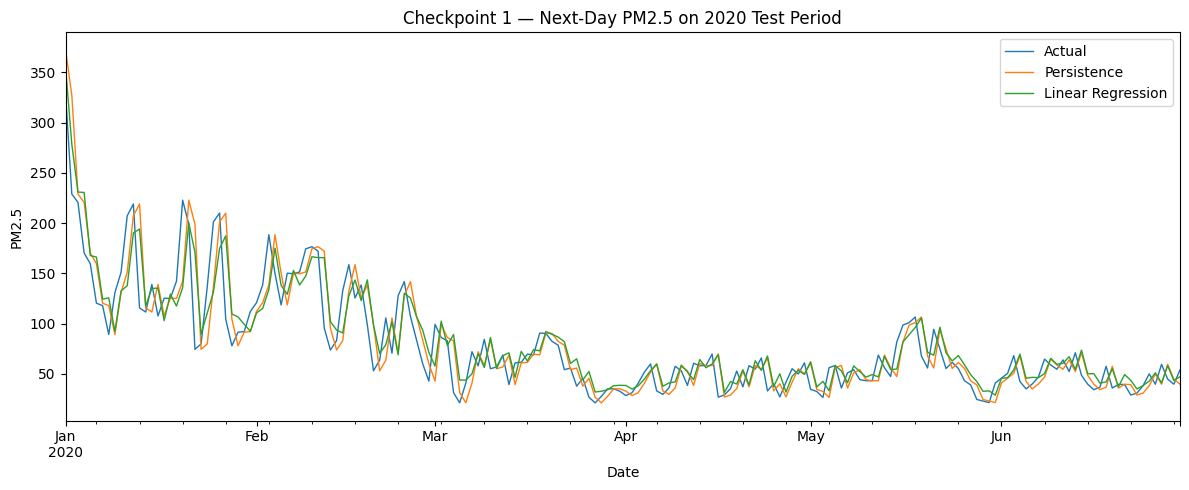

In [10]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Persistence": persistence_pred.loc[y_test.index],
    "Linear Regression": linear_pred,
}, index=y_test.index)

ax = comparison.plot(figsize=(12, 5), linewidth=1)
ax.set_title("Checkpoint 1 — Next-Day PM2.5 on 2020 Test Period")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5")
plt.tight_layout()
plt.show()

## 9. Save Checkpoint-1 outputs

The metrics and test predictions are saved so later phases can compare Ridge, Lasso and nonlinear models against the exact same persistence baseline.

In [11]:
# Find a sensible results folder whether the notebook is run from the project root or notebooks/.
if Path("results").exists() or Path("data").exists():
    RESULTS_DIR = Path("results")
elif Path("../results").exists():
    RESULTS_DIR = Path("../results")
else:
    RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metrics.to_csv(RESULTS_DIR / "checkpoint1_metrics.csv", index=False)
comparison.to_csv(RESULTS_DIR / "checkpoint1_predictions.csv", index_label="Date")

print("Saved:", RESULTS_DIR / "checkpoint1_metrics.csv")
print("Saved:", RESULTS_DIR / "checkpoint1_predictions.csv")

Saved: ../results/checkpoint1_metrics.csv
Saved: ../results/checkpoint1_predictions.csv


## Checkpoint-1 conclusion

On the held-out 2020 period, the Linear Regression model improves on the persistence baseline for both MAE and RMSE. The improvement is useful but not enormous, which is expected because persistence is already a strong benchmark for daily air quality.

This completes the modelling work required for **Phase B / Checkpoint 1**. The next phase should build the full lag, rolling and calendar feature set before Ridge, Lasso, nonlinear regression and AQI classification are attempted.